<a href="https://colab.research.google.com/github/OlhaHarkusha/Lab1_GroupProject/blob/main/%D0%9B%D1%8011_%D0%93%D0%B0%D1%80%D0%BA%D1%83%D1%88%D0%B0_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

from tensorflow.keras.layers import (
    Input, Rescaling, RandomFlip, RandomRotation, RandomContrast,  # виправлено RandonContrast
    Conv2D, BatchNormalization, MaxPool2D,
    GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras.regularizers import l2

# Перевірка GPU в Colab
print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Path to dataset files: /kaggle/input/gtsrb-german-traffic-sign


In [3]:
train_csv_path = "/kaggle/input/gtsrb-german-traffic-sign/Train.csv"
test_csv_path = "/kaggle/input/gtsrb-german-traffic-sign/Test.csv"
base_path = "/kaggle/input/gtsrb-german-traffic-sign"

train_df = pd.read_csv(train_csv_path)
test_df = pd.read_csv(test_csv_path)

train_df.head()

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


In [4]:
test_df.head()

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png


In [5]:
X_train = []
y_train = []

for _, row in train_df.iterrows():
    img_path = os.path.join(base_path, row["Path"])
    img = image.load_img(img_path, target_size=(32, 32))
    img_array = image.img_to_array(img)
    X_train.append(img_array)
    y_train.append(row["ClassId"])

X_train = np.array(X_train)
y_train = np.array(y_train)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (39209, 32, 32, 3)
y_train: (39209,)


In [6]:
X_test = []
y_test = []

for _, row in train_df.iterrows():
    img_path = os.path.join(base_path, row["Path"])
    img = image.load_img(img_path, target_size=(32, 32))
    img_array = image.img_to_array(img)
    X_test.append(img_array)
    y_test.append(row["ClassId"])

X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_test: (39209, 32, 32, 3)
y_test: (39209,)


In [7]:
print("Кількість класів:", len(np.unique(y_train)))

Кількість класів: 43


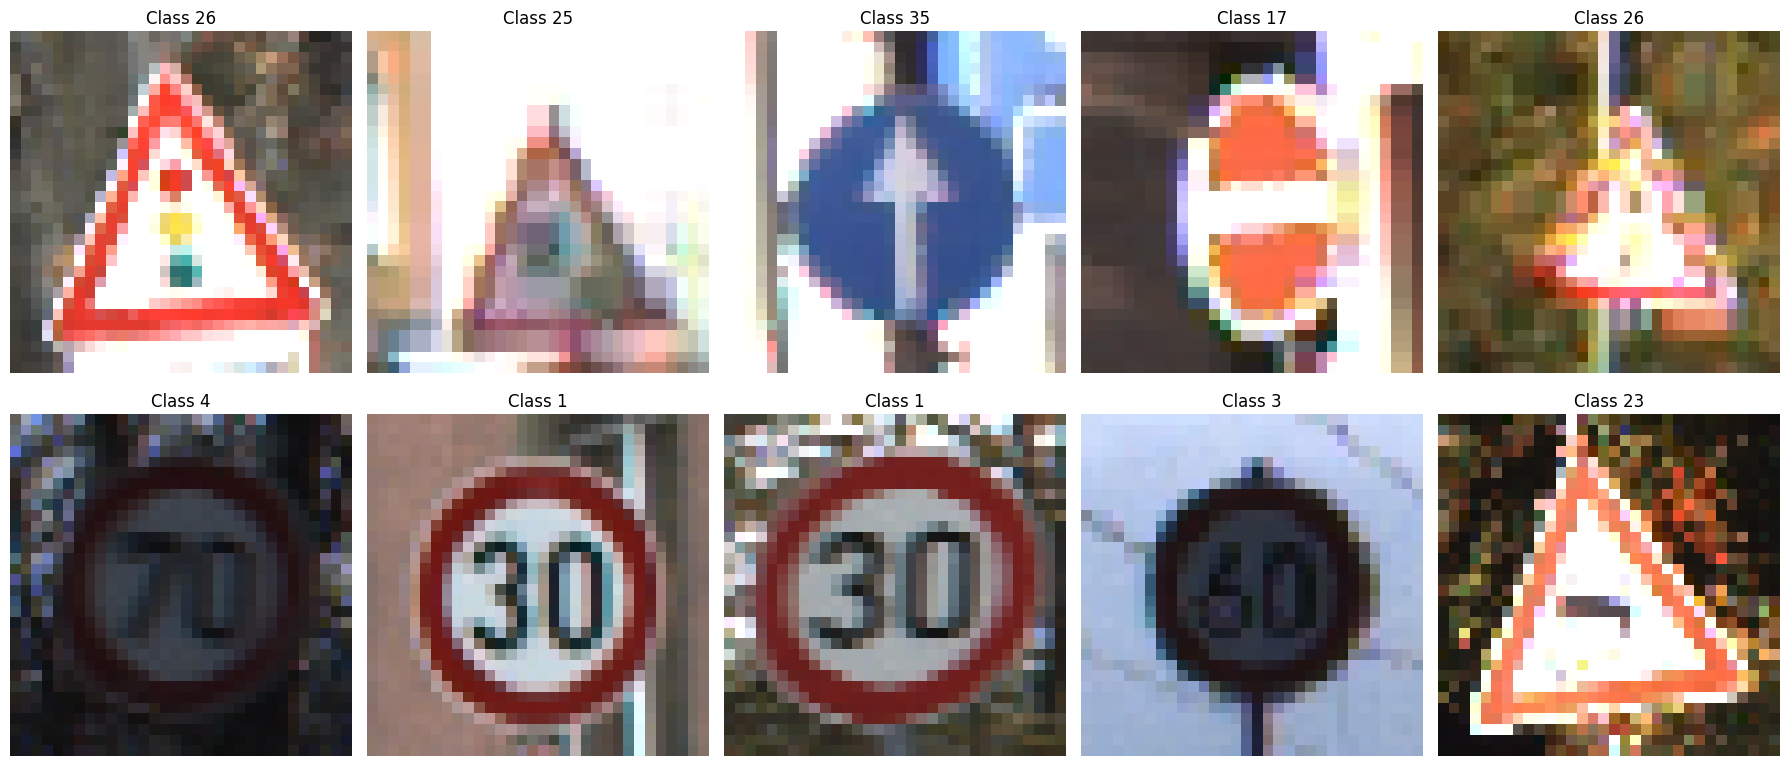

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import random

# Беремо 10 випадкових індексів
indices = random.sample(range(len(X_train)), 10)

plt.figure(figsize=(18, 8))

for i, idx in enumerate(indices):
    plt.subplot(2, 5, i + 1)
    img = X_train[idx]

    # Перевірка, чи зображення нормалізоване (від 0 до 1) чи ні
    if img.max() <= 1.0:
        plt.imshow(img)
    else:
        plt.imshow(img.astype('uint8'))

    # Отримуємо мітку класу. Перевіряємо, чи це one-hot (масив), чи просто число
    label = y_train[idx]
    if isinstance(label, (np.ndarray, list)) and len(label) > 1:
        class_id = np.argmax(label)
    else:
        class_id = int(label)

    plt.title(f"Class {class_id}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
y_train = to_categorical(y_train, num_classes=43)
y_test = to_categorical(y_test, num_classes=43)

print(f"Форма y_train після перетворення: {y_train.shape}")
print(f"Форма y_test після перетворення: {y_test.shape}")

Форма y_train після перетворення: (39209, 43)
Форма y_test після перетворення: (39209, 43)


In [12]:
height, width, channels = 32, 32, 3
NUM_CATEGORIES = 43

model = Sequential([
    Input(shape=(height, width, channels)),

    Rescaling(1./255),
    RandomFlip("horizontal"),
    RandomRotation(0.05),
    RandomContrast(0.1),

    # Блок 1
    Conv2D(32, (3,3), padding="same", activation="relu"),
    BatchNormalization(),
    Conv2D(32, (3,3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPool2D(),

    # Блок 2
    Conv2D(64, (3,3), padding="same", activation="relu"),
    BatchNormalization(),
    Conv2D(64, (3,3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPool2D(),

    # Блок 3
    Conv2D(128, (3,3), padding="same", activation="relu", kernel_regularizer=l2(1e-4)),
    BatchNormalization(),
    MaxPool2D(),

    GlobalAveragePooling2D(),
    Dropout(0.5),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(NUM_CATEGORIES, activation="softmax")
])

In [13]:
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.metrics import TopKCategoricalAccuracy

LOSS = CategoricalCrossentropy()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss=LOSS,
    metrics=[
        "accuracy",
        TopKCategoricalAccuracy(k=3, name="top3")
    ]
)

cb = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]

In [14]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=50,
    batch_size=32,
    shuffle=True,
    callbacks=cb,
    verbose=1
)

Epoch 1/50
1226/1226 ━━━━━━━━━━━━━━━━━━━━ 39s 22ms/step - accuracy: 0.2596 - loss: 2.7147 - top3: 0.4666 - val_accuracy: 0.5414 - val_loss: 1.5592 - val_top3: 0.7830 - learning_rate: 3.0000e-04
Epoch 2/50
1226/1226 ━━━━━━━━━━━━━━━━━━━━ 25s 20ms/step - accuracy: 0.5880 - loss: 1.3320 - top3: 0.8133 - val_accuracy: 0.8137 - val_loss: 0.6503 - val_top3: 0.9550 - learning_rate: 3.0000e-04
Epoch 3/50
1226/1226 ━━━━━━━━━━━━━━━━━━━━ 24s 20ms/step - accuracy: 0.7798 - loss: 0.7099 - top3: 0.9382 - val_accuracy: 0.9080 - val_loss: 0.3234 - val_top3: 0.9853 - learning_rate: 3.0000e-04
Epoch 4/50
1226/1226 ━━━━━━━━━━━━━━━━━━━━ 25s 20ms/step - accuracy: 0.8573 - loss: 0.4602 - top3: 0.9729 - val_accuracy: 0.9300 - val_loss: 0.2476 - val_top3: 0.9932 - learning_rate: 3.0000e-04
Epoch 5/50
1226/1226 ━━━━━━━━━━━━━━━━━━━━ 24s 20ms/step - accuracy: 0.8954 - loss: 0.3353 - top3: 0.9839 - val_accuracy: 0.9502 - val_loss: 0.1644 - val_top3: 0.9968 - learning_rate: 3.0000e-04
Epoch 6/50
1226/1226 ━━━━━━━━━

In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 32, 32, 3)      │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             

 Total params: 487,011 (1.86 MB)

 Trainable params: 162,123 (633.29 KB)

 Non-trainable params: 640 (2.50 KB)

 Optimizer params: 324,248 (1.24 MB)

In [16]:
training_accuracy = history.history["accuracy"]
training_loss = history.history["loss"]
validation_accuracy = history.history["val_accuracy"]
validation_loss = history.history["val_loss"]

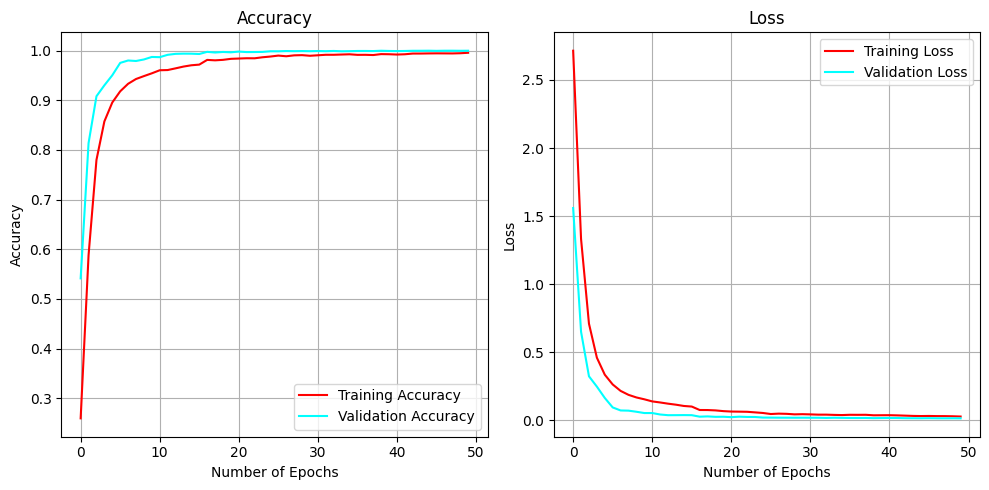

In [18]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.plot(training_accuracy, color="red", label="Training Accuracy")
plt.plot(validation_accuracy, color="cyan", label="Validation Accuracy")
plt.legend()
plt.grid(True)
plt.title("Accuracy")
plt.xlabel("Number of Epochs")
plt.ylabel("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(training_loss, color="red", label="Training Loss")
plt.plot(validation_loss, color="cyan", label="Validation Loss")
plt.grid(True)
plt.legend()
plt.title("Loss")
plt.xlabel("Number of Epochs")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 464ms/step


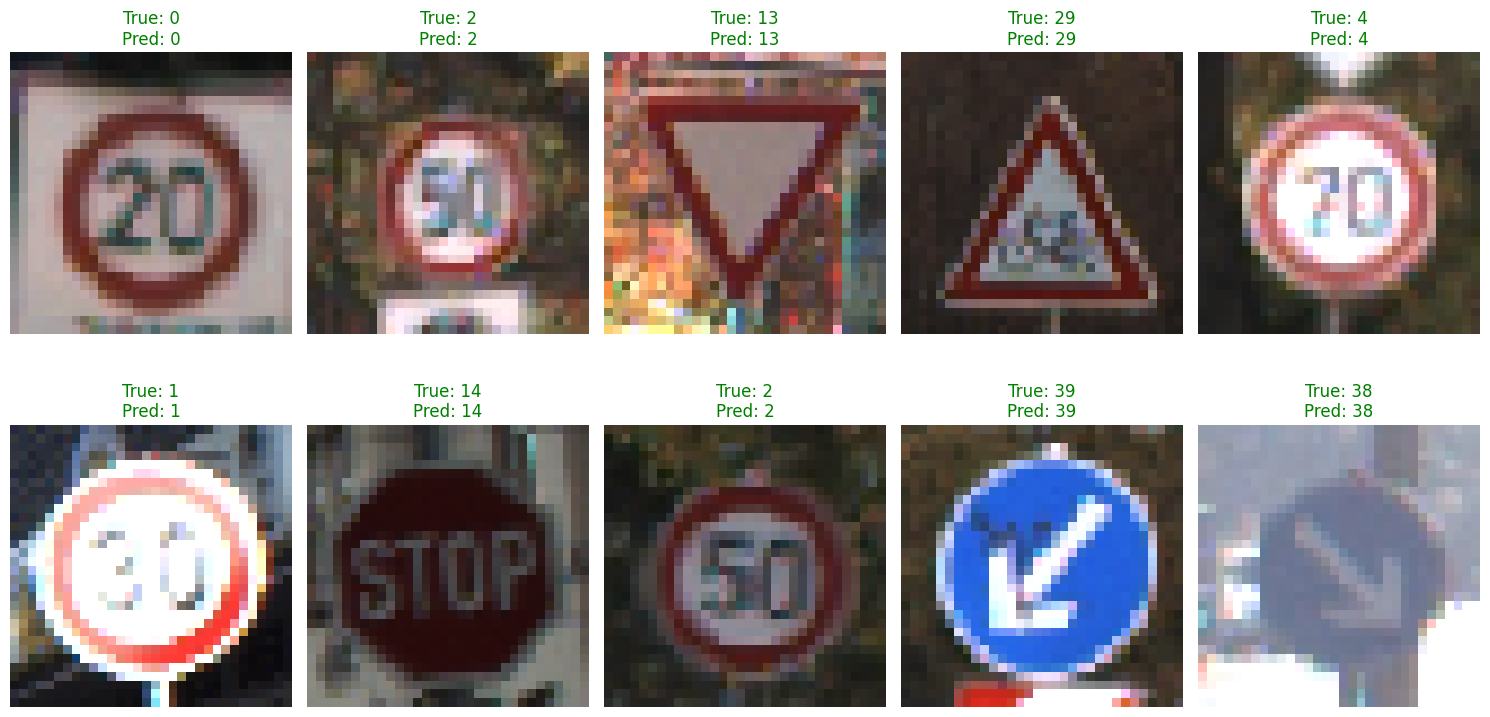

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import random

# беремо 10 випадкових картинок з тестової вибірки
indices = random.sample(range(len(X_test)), 10)

# створюємо sample_images і робимо передбачення
sample_images = X_test[indices]
y_pred = model.predict(sample_images)

# малюємо
plt.figure(figsize=(15, 8))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    img = sample_images[i]

    if img.max() <= 1.0:
        plt.imshow(img)
    else:
        plt.imshow(img.astype("uint8"))

    plt.axis("off")

    true_class = np.argmax(y_test[indices[i]])
    pred_class = np.argmax(y_pred[i])

    color = "green" if true_class == pred_class else "red"
    plt.title(f"True: {true_class}\nPred: {pred_class}", color=color)

plt.tight_layout()
plt.show()